# Studiul de caz 7 - Citirea graficelor de piață cu modele vizual-lingvistice: o alertă de anomalie pentru S&P 500

Master - Rețele neuronale și deep learning (NN) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/cases/C7_vlm_anomaly')

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Jheng, S.-L., Pele, D. T., Tak, R. și Găman, Ș. (2026). A multimodal vision-language framework for financial anomaly detection.
*Proceedings of the International Conference on Business Excellence (PICBE)*, 20(1), 191-201. doi:10.2478/picbe-2026-0020
(premiul pentru cea mai bună lucrare, Conferința internațională Business Excellence (ICBE) 2026).

**Conținutul notebook-ului.** (1) Calculăm indicatorii tehnici din lucrare pentru S&P 500 (indicele Standard & Poor's 500) și desenăm, pentru fiecare zi de
tranzacționare, un grafic standardizat cu cinci panouri pentru ultimele 126 de zile de tranzacționare. (2) Etichetăm o zi drept *zi de prăbușire* atunci cînd
randamentul logaritmic din ziua următoare scade sub cuantila glisantă de 5 % (și de 1 %) a ultimelor 126 de randamente zilnice, regula din lucrare (ec. 15-16).
(3) Clasificăm graficele cu modele vizual-lingvistice deschise: CLIP (*Contrastive Language-Image Pre-training*) fără antrenare (*zero-shot*), o sondă logistică
pe reprezentările CLIP ale imaginilor și Qwen2-VL-2B, care formulează și o justificare structurată. (4) Comparăm cu modele numerice pe aceiași indicatori:
o regulă de volatilitate, regresia logistică, gradient boosting și o rețea LSTM (*Long Short-Term Memory*), reperul folosit în lucrare.

**Adaptarea pentru curs și extinderea perioadei.** Lucrarea folosește GPT-4.1 (*generative pre-trained transformer*) cu imagini, un tabel de indicatori, titluri de
știri și contextul prețurilor, ianuarie 2005 - iunie 2025, cu testare în iulie 2024 - iunie 2025. Noi folosim modele deschise, care rulează pe un laptop, numai
imaginile (fără știri) și extindem perioada de test pînă în noiembrie 2026. Antrenare iulie 2006 - decembrie 2019, validare (alegerea modelului și a pragului)
ianuarie 2020 - iunie 2024, test din iulie 2024.

## 1. Datele, indicatorii și eticheta de prăbușire

In [3]:
os.environ.setdefault("OMP_NUM_THREADS", "1")   # one OpenMP runtime thread: PyTorch and scikit-learn share the process
import torch                       # imported before scikit-learn (course rule)
import io, json, re, time
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix
SEED = 20261108                    # seed of every random step below
np.random.seed(SEED); torch.manual_seed(SEED)
DEV = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("cache", exist_ok=True)

raw = pd.read_csv(os.path.join(cu.DATA, "markets_daily.csv"), parse_dates=["date"])
sp = raw[raw.ticker == "SP500"].set_index("date").sort_index()[["open", "high", "low", "close", "volume"]]
C, H, Lo, V = sp.close, sp.high, sp.low, sp.volume
r = np.log(C).diff()                                   # daily log return r_t
ema = lambda x, n: x.ewm(span=n, adjust=False).mean()

# the paper's indicators (eq. 2-14), computed with data up to day t only
ind = pd.DataFrame(index=sp.index)
for w in (10, 30, 120):
    ind[f"HV{w}"] = np.sqrt(252) * r.rolling(w).std() * 100                       # annualised volatility, %
TR = pd.concat([H - Lo, (H - C.shift()).abs(), (Lo - C.shift()).abs()], axis=1).max(axis=1)
ind["ATR14"] = ema(TR, 14) / C * 100                                               # average true range, % of price
macd = ema(C, 12) - ema(C, 26)
ind["MACD"] = macd / C * 100                                                       # % of price (comparable across years)
ind["MACDhist"] = (macd - ema(macd, 9)) / C * 100
dC = C.diff()
ind["RSI14"] = 100 - 100 / (1 + ema(dC.clip(lower=0), 14) / (ema((-dC).clip(lower=0), 14) + 1e-12))
sma20, sd20 = C.rolling(20).mean(), C.rolling(20).std()
ind["BBwidth"] = 4 * sd20 / sma20 * 100                                            # (upper - lower) / SMA20, %
ind["SMA50_200"] = (C.rolling(50).mean() / C.rolling(200).mean() - 1) * 100       # golden / death cross gap, %
dd20 = C / C.rolling(20).max() - 1
ind["MaxDD20"] = dd20.rolling(20).min() * 100                                      # eq. 10, %
ind["Ulcer14"] = np.sqrt(((C / C.rolling(14).max() - 1) * 100).pow(2).rolling(14).mean())
ind["VaR5"] = r.rolling(126).quantile(0.05) * 100
ind["VaR1"] = r.rolling(126).quantile(0.01) * 100
ind["ES5"] = r.rolling(126).apply(lambda x: x[x <= np.quantile(x, 0.05)].mean(), raw=True) * 100
obv = (np.sign(dC).fillna(0) * V).cumsum()
ind["OBV20"] = (obv - obv.shift(20)) / V.rolling(20).mean()                        # 20-day change of OBV, in days of volume
FEATS = list(ind.columns)

# crash label (paper eq. 15-16, horizon h = 1 day): next-day log return below the rolling alpha-quantile of the last 126 returns
fwd = r.shift(-1)
LAB = {a: (fwd < r.rolling(126).quantile(a)).astype(int) for a in (0.05, 0.01)}
TRAIN, VAL, TEST = ("2006-07-01", "2019-12-31"), ("2020-01-01", "2024-06-30"), ("2024-07-01", "2026-12-31")
days = ind.dropna().index
days = days[(days >= TRAIN[0]) & fwd.reindex(days).notna().values]
part = pd.Series(np.select([days <= TRAIN[1], days <= VAL[1]], ["train", "val"], "test"), index=days)
for nm in ("train", "val", "test"):
    d_ = part.index[part == nm]
    print(f"{nm:5s} {d_.min():%Y-%m-%d} - {d_.max():%Y-%m-%d}: {len(d_):5d} days, crash share 5 %: {100 * LAB[0.05][d_].mean():.1f} %, "
          f"1 %: {100 * LAB[0.01][d_].mean():.1f} %")

train 2006-07-03 - 2019-12-31:  3398 days, crash share 5 %: 5.8 %, 1 %: 2.0 %
val   2020-01-02 - 2024-06-28:  1130 days, crash share 5 %: 5.6 %, 1 %: 2.2 %
test  2024-07-01 - 2026-11-05:   591 days, crash share 5 %: 7.1 %, 1 %: 2.2 %


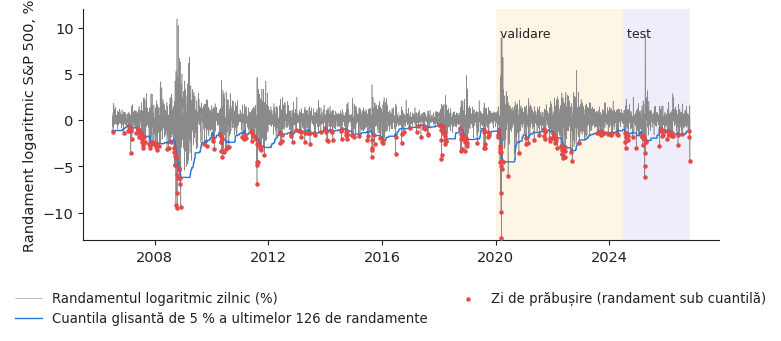

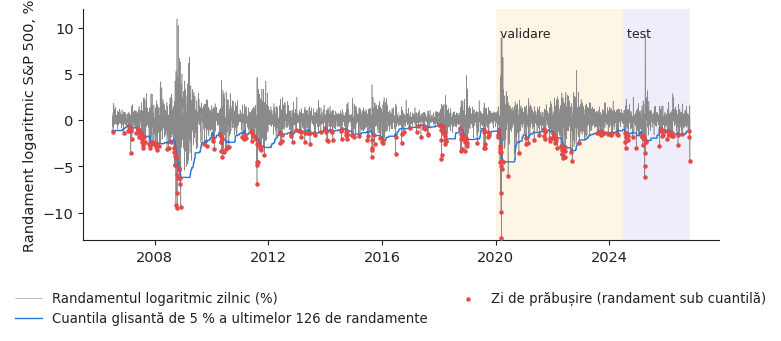

In [4]:
def fig_labels(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.0))
    rr = 100 * r.loc[days[0]:]
    q = 100 * r.rolling(126).quantile(0.05).loc[days[0]:]
    y5 = LAB[0.05].reindex(days)
    hit = days[y5.values == 1]
    ax.plot(rr.index, rr, color=cu.MUTED, lw=0.4, label=cu.T(lang, "Daily log return (%)", "Randamentul logaritmic zilnic (%)"))
    ax.plot(q.index, q, color=cu.PAL["RO"], lw=1.0, label=cu.T(lang, "Rolling 5 % quantile of the last 126 returns", "Cuantila glisantă de 5 % a ultimelor 126 de randamente"))
    nxt = [days[days.get_loc(d) + 1] if days.get_loc(d) + 1 < len(days) else d for d in hit]
    ax.scatter(nxt, 100 * fwd[hit], s=5, color=cu.EVENT, zorder=3, label=cu.T(lang, "Crash day (return below the quantile)", "Zi de prăbușire (randament sub cuantilă)"))
    for (a, b), c in [(VAL, cu.PAL["BG"]), (TEST, cu.PAL["c7"])]:
        ax.axvspan(pd.Timestamp(a), min(pd.Timestamp(b), days[-1]), color=c, alpha=0.10, lw=0)
    ax.text(pd.Timestamp(VAL[0]), 9, cu.T(lang, " validation", " validare"), fontsize=9)
    ax.text(pd.Timestamp(TEST[0]), 9, " test", fontsize=9)
    ax.set_ylim(-13, 12)
    ax.set_ylabel(cu.T(lang, "S&P 500 log return, %", "Randament logaritmic S&P 500, %"))
    cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_labels, "f2_labels")

## 2. Piața ca imagine: graficul standardizat cu cinci panouri

In [5]:
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.collections import LineCollection

W = 126                                                  # window length w (paper: 126 trading days)
PAN = {"en": ["Price, Bollinger bands, 50- and 200-day averages", "MACD and histogram", "RSI (14 days)",
              "Volatility HV10 and HV30 (%)", "Drawdown from the 20-day high (%)"],
       "ro": ["Preț, benzi Bollinger, medii pe 50 și 200 de zile", "MACD și histograma", "RSI (14 zile)",
              "Volatilitatea HV10 și HV30 (%)", "Scăderea față de maximul pe 20 de zile (%)"]}
sma50, sma200 = C.rolling(50).mean(), C.rolling(200).mean()
macd_sig = ema(macd, 9)
pos = {d: i for i, d in enumerate(C.index)}

class Chart:
    """Renders the chart of day t (last W trading days) to an RGB image; one figure is reused for speed. The model input is the English version."""
    def __init__(self, lang="en", px=448):
        self.fig = Figure(figsize=(px / 100, px / 100), dpi=100, facecolor="white")
        FigureCanvasAgg(self.fig)
        gs = self.fig.add_gridspec(5, 1, height_ratios=[2.6, 1.2, 1.2, 1.2, 1.2], hspace=0.55, left=0.1, right=0.98, top=0.95, bottom=0.03)
        self.ax = [self.fig.add_subplot(gs[k]) for k in range(5)]
        for a, t in zip(self.ax, PAN[lang]):
            a.set_title(t, fontsize=6.5, loc="left", pad=2)
            a.set_xticks([]); a.tick_params(labelsize=5, length=2, pad=1)
            a.set_facecolor("white")
            for s in ("top", "right"):
                a.spines[s].set_visible(False)
        x = np.arange(W)
        a0, a1, a2, a3, a4 = self.ax
        self.l = {"p": a0.plot(x, x, color="#1f4e9a", lw=1.0)[0], "bu": a0.plot(x, x, color="#999999", lw=0.6)[0],
                  "bl": a0.plot(x, x, color="#999999", lw=0.6)[0], "s50": a0.plot(x, x, color="#eb6834", lw=0.8)[0],
                  "s200": a0.plot(x, x, color="#1baf7a", lw=0.8)[0], "m": a1.plot(x, x, color="#1f4e9a", lw=0.8)[0],
                  "ms": a1.plot(x, x, color="#eb6834", lw=0.7)[0], "rsi": a2.plot(x, x, color="#6250d6", lw=0.8)[0],
                  "h10": a3.plot(x, x, color="#e34948", lw=0.8)[0], "h30": a3.plot(x, x, color="#1f4e9a", lw=0.8)[0],
                  "dd": a4.plot(x, x, color="#e34948", lw=0.8)[0]}
        self.bars = LineCollection([], colors="#8a8a8a", linewidths=1.2)
        a1.add_collection(self.bars)
        for v in (30, 70):
            a2.axhline(v, color="#bbbbbb", lw=0.5)
        a2.set_ylim(0, 100)
        a1.axhline(0, color="#bbbbbb", lw=0.5)
        for a in self.ax:
            a.set_xlim(-1, W)

    def __call__(self, t):
        i = pos[t]
        s = slice(i - W + 1, i + 1)
        seg = lambda z: z.iloc[s].values
        for k, z in [("p", C), ("bu", sma20 + 2 * sd20), ("bl", sma20 - 2 * sd20), ("s50", sma50), ("s200", sma200),
                     ("m", macd / C * 100), ("ms", macd_sig / C * 100), ("rsi", ind.RSI14), ("h10", ind.HV10), ("h30", ind.HV30), ("dd", 100 * dd20)]:
            self.l[k].set_ydata(seg(z))
        hist = seg((macd - macd_sig) / C * 100)
        self.bars.set_segments([[(j, 0), (j, h)] for j, h in enumerate(hist)])
        lims = [np.r_[seg(C), seg(sma20 - 2 * sd20), seg(sma20 + 2 * sd20), seg(sma50), seg(sma200)],
                np.r_[seg(macd / C * 100), seg(macd_sig / C * 100), hist], None, np.r_[seg(ind.HV10), seg(ind.HV30)], np.r_[seg(100 * dd20), 0]]
        for a, v in zip(self.ax, lims):
            if v is not None:
                lo, hi = np.nanmin(v), np.nanmax(v)
                pad = 0.06 * (hi - lo + 1e-9)
                a.set_ylim(lo - pad, hi + pad)
        self.fig.canvas.draw()
        return Image.fromarray(np.asarray(self.fig.canvas.buffer_rgba())[..., :3].copy())

chart = Chart("en")
t0 = time.time(); _ = chart(days[-1]); print(f"one chart: {1000 * (time.time() - t0):.0f} ms, size {_.size}")

one chart: 24 ms, size (448, 448)


calm day 2024-12-02  day before the largest fall 2025-04-03 next-day return -6.16 %


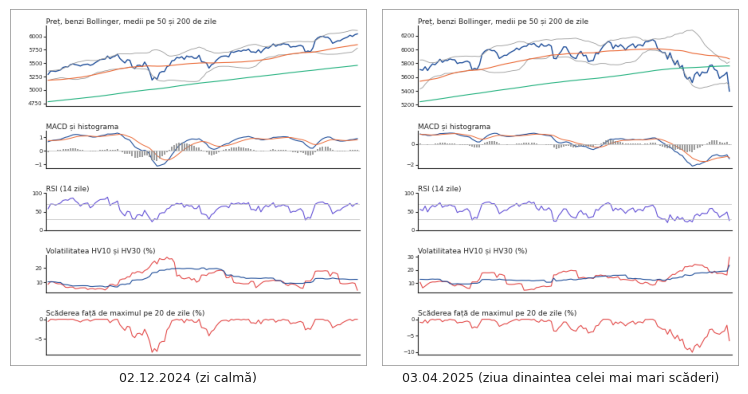

In [6]:
# two example charts: a calm test day and the day before the largest one-day fall of the test period
te_days = part.index[part == "test"]
d_crash = fwd[te_days].idxmin()                                    # chart seen on the evening before the largest fall
d_calm = ind.HV10[te_days].idxmin()                                # calmest test day (lowest 10-day volatility)
def fig_images(lang):
    ch = Chart(lang, px=448)
    fig, axs = plt.subplots(1, 2, figsize=(7.6, 3.9))
    for a, d, lab in [(axs[0], d_calm, cu.T(lang, "calm day", "zi calmă")), (axs[1], d_crash, cu.T(lang, "day before the largest fall", "ziua dinaintea celei mai mari scăderi"))]:
        a.imshow(ch(d)); a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values():
            s.set_visible(True); s.set_color(cu.MUTED); s.set_linewidth(0.5)
        a.set_xlabel((f"{d:%Y-%m-%d}" if lang == "en" else f"{d:%d.%m.%Y}") + f" ({lab})", fontsize=9)
    fig.tight_layout()
    return fig
cu.save_both(fig_images, "f1_images")
print("calm day", d_calm.date(), " day before the largest fall", d_crash.date(), f"next-day return {100 * fwd[d_crash]:.2f} %")

## 3. CLIP: reprezentările imaginilor, scoruri zero-shot și o sondă logistică

In [7]:
from transformers import CLIPModel, CLIPProcessor
CLIP_ID = "openai/clip-vit-base-patch16"                         # ViT-B/16, the CLIP model of Lecture 14
clip, cproc = CLIPModel.from_pretrained(CLIP_ID).to(DEV).eval(), CLIPProcessor.from_pretrained(CLIP_ID)

def feats(out):
    return out if isinstance(out, torch.Tensor) else out.pooler_output

EPATH = os.path.join("cache", "clip_B16_charts.npz")
if os.path.isfile(EPATH) and len(np.load(EPATH)["dates"]) == len(days):
    E = np.load(EPATH)["E"]
else:                                                              # renders every chart once and keeps only its 512-dimensional embedding
    t0, out, buf = time.time(), [], []
    with torch.no_grad():
        for k, d in enumerate(days):
            buf.append(chart(d))
            if len(buf) == 64 or k == len(days) - 1:
                px_ = cproc(images=buf, return_tensors="pt")["pixel_values"].to(DEV)
                out.append(torch.nn.functional.normalize(feats(clip.get_image_features(pixel_values=px_)).float(), dim=-1).cpu().numpy())
                buf = []
    E = np.concatenate(out)
    np.savez(EPATH, E=E, dates=days.values.astype("datetime64[D]").astype(str))
    print(f"rendered and embedded {len(days)} charts in {time.time() - t0:.0f} s")
print("embeddings", E.shape)

PROMPTS = {0: ["a financial chart of a calm stock market rising steadily with low volatility",
               "a chart of a stable bull market with low and falling volatility",
               "technical indicators of a quiet, healthy stock market"],
           1: ["a financial chart of a stressed stock market falling sharply with rising volatility and a deep drawdown",
               "a chart of a market crash with spiking volatility and oversold momentum",
               "technical indicators warning of an imminent stock market crash"]}
with torch.no_grad():
    Tx = {c: torch.nn.functional.normalize(feats(clip.get_text_features(**cproc(text=p, return_tensors="pt", padding=True).to(DEV))).float(), dim=-1).mean(0).cpu().numpy()
          for c, p in PROMPTS.items()}
S = {"clip_zs": pd.Series(E @ Tx[1] - E @ Tx[0], index=days)}   # zero-shot score: cosine(stress) - cosine(calm)
del clip

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

embeddings (5119, 512)


## 4. Modelele: reperele numerice, sonda CLIP, LSTM

In [8]:
itr, iva, ite = (part == "train").values, (part == "val").values, (part == "test").values
X = ind.loc[days, FEATS].values
mu, sd = X[itr].mean(0), X[itr].std(0)
Xs = (X - mu) / sd
Em, Es = E[itr].mean(0), E[itr].std(0) + 1e-6
Ez = (E - Em) / Es
SC = {0.05: {}, 0.01: {}}
for a in (0.05, 0.01):
    y = LAB[a].loc[days].values
    SC[a]["vol"] = ind.HV10.loc[days].values                                  # volatility rule: no training
    SC[a]["clip_zs"] = S["clip_zs"].values
    lr = LogisticRegression(max_iter=5000, class_weight="balanced").fit(Xs[itr], y[itr])
    SC[a]["logit"] = lr.predict_proba(Xs)[:, 1]
    w_ = np.where(y[itr] == 1, 0.5 / y[itr].mean(), 0.5 / (1 - y[itr].mean()))
    hgb = GradientBoostingClassifier(max_depth=3, learning_rate=0.05, n_estimators=300, subsample=0.8, random_state=SEED)
    SC[a]["hgb"] = hgb.fit(Xs[itr], y[itr], sample_weight=w_).predict_proba(Xs)[:, 1]
    best = None
    for Cc in (0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0):                                         # probe strength chosen on the validation AUC
        pr = LogisticRegression(max_iter=5000, C=Cc, class_weight="balanced").fit(Ez[itr], y[itr])
        s_ = pr.predict_proba(Ez)[:, 1]
        auc_v = roc_auc_score(y[iva], s_[iva])
        if best is None or auc_v > best[0]:
            best = (auc_v, Cc, s_)
    SC[a]["clip_probe"] = best[2]
    print(f"alpha {a}: CLIP probe C = {best[1]} (validation AUC {best[0]:.3f})")

alpha 0.05: CLIP probe C = 0.001 (validation AUC 0.677)


alpha 0.01: CLIP probe C = 1e-05 (validation AUC 0.719)


In [9]:
# LSTM on the last 20 days of the 15 indicators (the paper's baseline), early stopping on the validation AUC, 3 seeds averaged
torch.set_num_threads(2)
L_SEQ = 20
seq_idx = np.array([pos[d] for d in days])
Xall = ((ind[FEATS] - mu) / sd).fillna(0).values.astype(np.float32)
SEQ = torch.tensor(np.stack([Xall[i - L_SEQ + 1:i + 1] for i in seq_idx]))

class LSTMNet(torch.nn.Module):
    def __init__(self, d, h=32):
        super().__init__()
        self.lstm = torch.nn.LSTM(d, h, batch_first=True)
        self.drop = torch.nn.Dropout(0.2)
        self.out = torch.nn.Linear(h, 1)
    def forward(self, x):
        return self.out(self.drop(self.lstm(x)[0][:, -1])).squeeze(-1)

def fit_lstm(y, seed, epochs=25):
    torch.manual_seed(seed); np.random.seed(seed)
    net = LSTMNet(len(FEATS))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    yt = torch.tensor(y, dtype=torch.float32)
    lossf = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - y[itr].mean()) / y[itr].mean()))
    tr_i = np.where(itr)[0]
    best = (-1, None)
    for ep in range(epochs):
        net.train()
        for b in np.array_split(np.random.permutation(tr_i), len(tr_i) // 128):
            opt.zero_grad(); loss = lossf(net(SEQ[b]), yt[b]); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            s_ = torch.sigmoid(net(SEQ)).numpy()
        auc_v = roc_auc_score(y[iva], s_[iva])
        if auc_v > best[0]:
            best = (auc_v, s_)
    return best
LSTM_SEEDS = [1, 2, 3]
lstm_seed_auc = {}
for a in (0.05, 0.01):
    y = LAB[a].loc[days].values
    runs = [fit_lstm(y, s) for s in LSTM_SEEDS]
    SC[a]["lstm"] = np.mean([b[1] for b in runs], axis=0)
    lstm_seed_auc[a] = [roc_auc_score(y[ite], b[1][ite]) for b in runs]
    print(f"alpha {a}: LSTM test AUC by seed", np.round(lstm_seed_auc[a], 3))

alpha 0.05: LSTM test AUC by seed [0.73  0.724 0.715]


alpha 0.01: LSTM test AUC by seed [0.648 0.651 0.637]


## 5. Qwen2-VL-2B: un model vizual-lingvistic citește graficul

In [10]:
from transformers import AutoProcessor, Qwen2VLForConditionalGeneration
VL = "Qwen/Qwen2-VL-2B-Instruct"
_vl = {}
def vl():
    if not _vl:
        p = AutoProcessor.from_pretrained(VL, min_pixels=256 * 28 * 28, max_pixels=256 * 28 * 28)
        p.tokenizer.padding_side = "left"
        m = Qwen2VLForConditionalGeneration.from_pretrained(VL, dtype=torch.float16 if DEV != "cpu" else torch.float32).to(DEV).eval()
        _vl.update(p=p, m=m)
    return _vl["p"], _vl["m"]

DESC = ("This image shows technical indicators of the S&P 500 stock index over the last 126 trading days, in five panels: price with Bollinger bands "
        "and 50- and 200-day moving averages; MACD and its histogram; RSI (14 days); volatility HV10 and HV30; drawdown from the 20-day high. ")
Q_YN = DESC + "Is there a high risk of a sharp market fall (a crash) on the next trading day? Answer yes or no."
VPATH = os.path.join("cache", "qwen2vl_yesno.csv")
eval_days = days[iva | ite]                                       # validation (threshold) and test
if os.path.isfile(VPATH) and len(pd.read_csv(VPATH)) == len(eval_days):
    qv = pd.read_csv(VPATH, parse_dates=["date"]).set_index("date")["p_yes"]
else:
    p, m = vl(); tok = p.tokenizer
    ids = [[tok.encode(w)[0] for w in (v, v.capitalize(), " " + v)] for v in ("yes", "no")]
    txt = p.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": Q_YN}]}], add_generation_prompt=True)
    t0, out = time.time(), []
    with torch.no_grad():
        for j in range(0, len(eval_days), 8):
            ims = [chart(d) for d in eval_days[j:j + 8]]
            inp = p(text=[txt] * len(ims), images=ims, return_tensors="pt", padding=True).to(DEV)
            pr = torch.softmax(m(**inp).logits[:, -1].float(), -1)
            a2 = torch.stack([pr[:, list(set(i))].sum(1) for i in ids], 1)
            out.append((a2[:, 0] / a2.sum(1)).cpu().numpy())
    qv = pd.Series(np.concatenate(out), index=eval_days, name="p_yes")
    qv.rename_axis("date").reset_index().to_csv(VPATH, index=False)
    print(f"Qwen2-VL yes/no on {len(eval_days)} charts in {time.time() - t0:.0f} s")
for a in (0.05, 0.01):
    SC[a]["qwen"] = qv.reindex(days).values                       # not scored on the training years (zero-shot, no training needed)

In [11]:
# structured answers (the paper's output format: score, label, type, key signals, reasoning) for a few test days
Q_JS = DESC + ("Act as a risk analyst. Return only a JSON object with the keys anomaly_score (a number from 0 to 1), anomaly_label (0 or 1), "
               "anomaly_type (a short phrase), key_signals (a list of three short phrases read from the chart) and reasoning (two sentences) "
               "about the risk of a sharp fall on the next trading day.")
JPATH = os.path.join("cache", "qwen2vl_json.json")
y5t = LAB[0.05][te_days]
ask = list(fwd[te_days].nsmallest(3).index) + list(ind.HV10[te_days].nsmallest(3).index)
if os.path.isfile(JPATH):
    JS = json.load(open(JPATH, encoding="utf-8"))
else:
    p, m = vl()
    txt = p.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": Q_JS}]}], add_generation_prompt=True)
    JS = {}
    with torch.no_grad():
        for d in ask:
            inp = p(text=[txt], images=[chart(d)], return_tensors="pt").to(DEV)
            g = m.generate(**inp, max_new_tokens=400, do_sample=False)
            JS[f"{d:%Y-%m-%d}"] = p.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()
    json.dump(JS, open(JPATH, "w", encoding="utf-8"), indent=1, ensure_ascii=False)
def parse(s):
    """JSON answer of the model; if the text is cut or malformed, read the fields one by one."""
    try:
        return json.loads(re.search(r"\{.*\}", s, re.S).group(0))
    except Exception:
        out = {}
        for k in ("anomaly_score", "anomaly_label"):
            m_ = re.search(r'"%s"\s*:\s*([-0-9.]+)' % k, s)
            if m_:
                out[k] = float(m_.group(1))
        for k in ("anomaly_type", "reasoning"):
            m_ = re.search(r'"%s"\s*:\s*"([^"]*)' % k, s)
            if m_:
                out[k] = m_.group(1)
        m_ = re.search(r'"key_signals"\s*:\s*\[(.*?)\]', s, re.S)
        if m_:
            out["key_signals"] = re.findall(r'"([^"]*)"', m_.group(1))
        return out
for d, s in JS.items():
    j = parse(s)
    print(d, f"next-day return {100 * fwd[pd.Timestamp(d)]:+.2f} %, crash label {int(LAB[0.05][pd.Timestamp(d)])}:",
          {k: j.get(k) for k in ("anomaly_score", "anomaly_label", "anomaly_type")})
print("\n", JS[f"{d_crash:%Y-%m-%d}"])

2025-04-03 next-day return -6.16 %, crash label 1: {'anomaly_score': 0.0, 'anomaly_label': 0, 'anomaly_type': 'No apparent anomaly'}
2025-04-02 next-day return -4.96 %, crash label 1: {'anomaly_score': 0.0, 'anomaly_label': 0, 'anomaly_type': 'No apparent anomaly'}
2026-11-04 next-day return -4.45 %, crash label 1: {'anomaly_score': 0.0, 'anomaly_label': 0, 'anomaly_type': 'No apparent anomaly'}
2024-12-02 next-day return +0.05 %, crash label 0: {'anomaly_score': 0.0, 'anomaly_label': 0, 'anomaly_type': 'No apparent anomaly'}
2024-12-03 next-day return +0.60 %, crash label 0: {'anomaly_score': 0.0, 'anomaly_label': 0, 'anomaly_type': 'No apparent anomaly'}
2024-07-09 next-day return +1.02 %, crash label 0: {'anomaly_score': 0.0, 'anomaly_label': 0, 'anomaly_type': 'No apparent anomaly'}

 ```json
{
  "anomaly_score": 0.0,
  "anomaly_label": 0,
  "anomaly_type": "No apparent anomaly",
  "key_signals": ["Price is above the 50-day moving average and the 200-day moving average", "MACD is p

## 6. Evaluarea pe date noi și decizia de alertă

In [12]:
NAMES = {"vol": ("Volatility rule (HV10)", "Regula volatilității (HV10)"),
         "logit": ("Logistic regression, 15 indicators", "Regresie logistică, 15 indicatori"),
         "hgb": ("Gradient boosting, 15 indicators", "Gradient boosting, 15 indicatori"),
         "lstm": ("LSTM, 20 days of indicators", "LSTM, 20 de zile de indicatori"),
         "clip_zs": ("CLIP zero-shot (chart + text prompts)", "CLIP zero-shot (grafic + descrieri text)"),
         "clip_probe": ("CLIP chart embedding + logistic probe", "Reprezentarea CLIP a graficului + sondă logistică"),
         "qwen": ("Qwen2-VL-2B zero-shot (yes/no)", "Qwen2-VL-2B zero-shot (da/nu)")}
KEYS = list(NAMES)
rng = np.random.default_rng(SEED)
BOOT = [rng.integers(0, ite.sum(), ite.sum()) for _ in range(1000)]

def evaluate(a, k):
    y = LAB[a].loc[days].values
    s = SC[a][k]
    sv, yv = s[iva], y[iva]
    cand = np.unique(np.quantile(sv, np.linspace(0.5, 0.995, 120)))
    f1v = [2 * ((sv >= c) & (yv == 1)).sum() / ((sv >= c).sum() + yv.sum()) for c in cand]
    tau = cand[int(np.argmax(f1v))]                               # alert threshold chosen on the validation period (max F1)
    st, yt = s[ite], y[ite]
    al = st >= tau
    tn, fp, fn, tp = confusion_matrix(yt, al, labels=[0, 1]).ravel()
    auc = roc_auc_score(yt, st)
    bs = [roc_auc_score(yt[b], st[b]) for b in BOOT if 0 < yt[b].sum() < len(b)]
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return dict(AUC=auc, lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5), AUCval=roc_auc_score(yv, sv), tau=tau,
                Precision=prec, Recall=rec, F1=2 * prec * rec / max(prec + rec, 1e-12), BalAcc=0.5 * (rec + tn / (tn + fp)),
                Accuracy=(tp + tn) / len(yt), TP=tp, FP=fp, TN=tn, FN=fn, alerts=al)
R = {a: {k: evaluate(a, k) for k in KEYS} for a in (0.05, 0.01)}
res = pd.DataFrame({k: {c: v for c, v in R[0.05][k].items() if c != "alerts"} for k in KEYS}).T
res["AUC1"] = [R[0.01][k]["AUC"] for k in KEYS]
res["AUCval1"] = [R[0.01][k]["AUCval"] for k in KEYS]
for c in ("TP", "FP", "TN", "FN"):
    res[c + "1"] = [R[0.01][k][c] for k in KEYS]
print(f"test: {ite.sum()} days, crash days 5 %: {int(LAB[0.05].loc[days][ite].sum())}, 1 %: {int(LAB[0.01].loc[days][ite].sum())}")
res[["AUCval", "AUC", "lo", "hi", "Precision", "Recall", "F1", "BalAcc", "TP", "FP", "TN", "FN", "AUCval1", "AUC1"]].round(3)

test: 591 days, crash days 5 %: 42, 1 %: 13


,AUCval,AUC,lo,hi,Precision,Recall,F1,BalAcc,TP,FP,TN,FN,AUCval1,AUC1
vol,0.555,0.552,0.456,0.651,0.231,0.071,0.109,0.527,3.0,10.0,539.0,39.0,0.629,0.548
logit,0.738,0.735,0.671,0.796,0.138,0.524,0.218,0.636,22.0,138.0,411.0,20.0,0.755,0.685
hgb,0.708,0.749,0.682,0.812,0.144,0.690,0.239,0.689,29.0,172.0,377.0,13.0,0.735,0.669
lstm,0.754,0.726,0.661,0.793,0.130,0.167,0.146,0.541,7.0,47.0,502.0,35.0,0.792,0.643
clip_zs,0.532,0.459,0.363,0.559,0.129,0.095,0.110,0.523,4.0,27.0,522.0,38.0,0.518,0.385
clip_probe,0.677,0.598,0.525,0.679,0.027,0.024,0.025,0.479,1.0,36.0,513.0,41.0,0.719,0.652
qwen,0.540,0.496,0.401,0.592,0.069,0.310,0.113,0.494,13.0,176.0,373.0,29.0,0.560,0.543


In [13]:
T1 = pd.DataFrame({"AUC": res.AUC, "CI": [(f"[{cu.fmt(l_, 2)}, {cu.fmt(h_, 2)}]", f"[{cu.fmt(l_, 2, 'ro')}; {cu.fmt(h_, 2, 'ro')}]") for l_, h_ in zip(res.lo, res.hi)],
                   "Precision": res.Precision, "Recall": res.Recall, "F1": res.F1, "BalAcc": res.BalAcc, "AUC1": res.AUC1})
T1.index = [NAMES[k] for k in KEYS]
cu.write_table(T1, "perf", [("Model", "Model"), ("AUC", "AUC"), ("95\\,\\% CI", "IÎ 95\\,\\%"), ("Precision", "Precizie"), ("Recall", "Sensibilitate"),
                            ("F1", "F1"), ("Bal.\\ acc.", "Acur.\\ echil."), ("AUC, $\\alpha$=1\\,\\%", "AUC, $\\alpha$=1\\,\\%")],
               digits=3, best={"AUC": "max", "Precision": "max", "Recall": "max", "F1": "max", "BalAcc": "max", "AUC1": "max"})
T2 = res[["TP", "FP", "TN", "FN", "TP1", "FP1", "TN1", "FN1"]].astype(int)
T2.index = [NAMES[k] for k in KEYS]
cu.write_table(T2, "confusion", [("Model", "Model")] + [(f"{c}$_{{{q}}}$", f"{c}$_{{{q}}}$") for q in ("5", "1") for c in ("TP", "FP", "TN", "FN")],
               digits=0)
cu.show_table(T1.drop(columns="CI"), best={"AUC": "max", "F1": "max"}, digits=3)

,AUC,Precision,Recall,F1,BalAcc,AUC1
"('Volatility rule (HV10)', 'Regula volatilității (HV10)')",0.552,0.231,0.071,0.109,0.527,0.548
"('Logistic regression, 15 indicators', 'Regresie logistică, 15 indicatori')",0.735,0.138,0.524,0.218,0.636,0.685
"('Gradient boosting, 15 indicators', 'Gradient boosting, 15 indicatori')",0.749,0.144,0.690,0.239,0.689,0.669
"('LSTM, 20 days of indicators', 'LSTM, 20 de zile de indicatori')",0.726,0.130,0.167,0.146,0.541,0.643
"('CLIP zero-shot (chart + text prompts)', 'CLIP zero-shot (grafic + descrieri text)')",0.459,0.129,0.095,0.110,0.523,0.385
"('CLIP chart embedding + logistic probe', 'Reprezentarea CLIP a graficului + sondă logistică')",0.598,0.027,0.024,0.025,0.479,0.652
"('Qwen2-VL-2B zero-shot (yes/no)', 'Qwen2-VL-2B zero-shot (da/nu)')",0.496,0.069,0.310,0.113,0.494,0.543


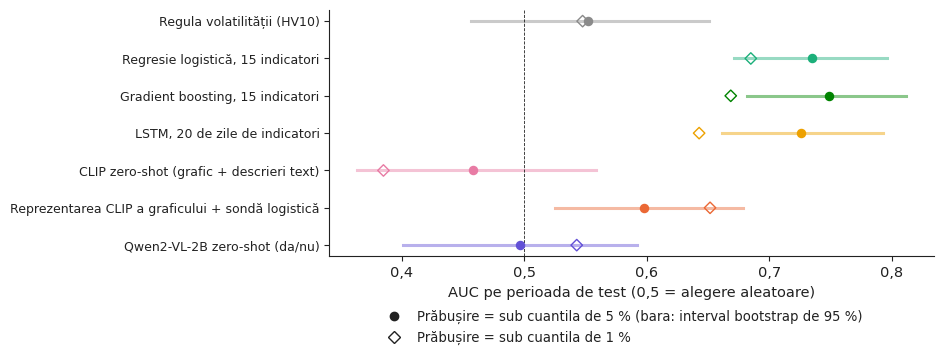

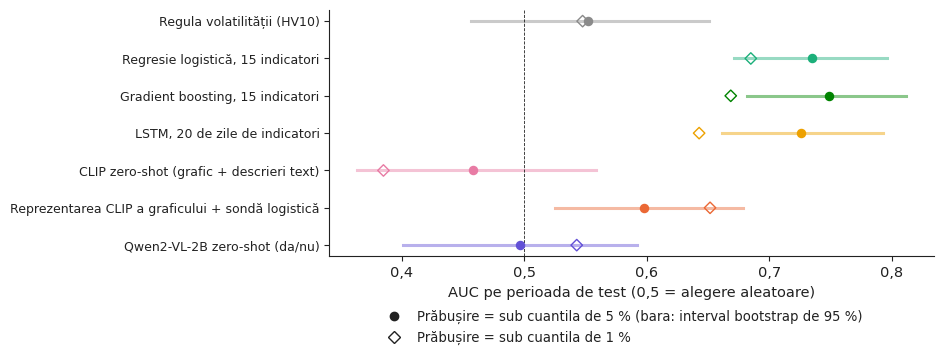

In [14]:
COL = {"vol": cu.MUTED, "logit": cu.PAL["HU"], "hgb": cu.PAL["c6"], "lstm": cu.PAL["BG"], "clip_zs": cu.PAL["c5"],
       "clip_probe": cu.PAL["DE_LU"], "qwen": cu.PAL["c7"]}
def fig_auc(lang):
    fig, ax = plt.subplots(figsize=(7.8, 3.2))
    yy = np.arange(len(KEYS))[::-1]
    for j, k in zip(yy, KEYS):
        ax.plot([res.lo[k], res.hi[k]], [j, j], color=COL[k], lw=2.2, alpha=0.45)
        ax.scatter(res.AUC[k], j, color=COL[k], s=34, zorder=3)
        ax.scatter(res.AUC1[k], j, color=COL[k], s=34, marker="D", facecolors="none", zorder=3)
    ax.axvline(0.5, color=cu.INK, lw=0.6, ls="--")
    ax.set_yticks(yy); ax.set_yticklabels([cu.T(lang, *NAMES[k]) for k in KEYS], fontsize=9)
    ax.set_xlabel(cu.T(lang, "Test AUC (0.5 = chance)", "AUC pe perioada de test (0,5 = alegere aleatoare)"))
    h = [plt.Line2D([], [], color=cu.INK, marker="o", ls="", label=cu.T(lang, "Crash = below the 5 % quantile (bar: 95 % bootstrap interval)",
                                                                           "Prăbușire = sub cuantila de 5 % (bara: interval bootstrap de 95 %)")),
         plt.Line2D([], [], color=cu.INK, marker="D", mfc="none", ls="", label=cu.T(lang, "Crash = below the 1 % quantile", "Prăbușire = sub cuantila de 1 %"))]
    cu.comma_axis(ax, lang, "x")
    cu.legend_bottom(fig, ncol=1, handles=h, labels=[x.get_label() for x in h])
    return fig
cu.save_both(fig_auc, "f3_auc")

{'best': ('LSTM, 20 days of indicators', 'LSTM, 20 de zile de indicatori'), 'alerts': 54, 'perMonth': np.float64(1.9180396732788798), 'caught': np.float64(16.666666666666668), 'retAlert': np.float64(0.3686835985666449), 'retQuiet': np.float64(0.018445107372303888), 'sdAlert': np.float64(1.7869885047222371), 'sdQuiet': np.float64(0.895739208131813), 'worstCaught': 3}


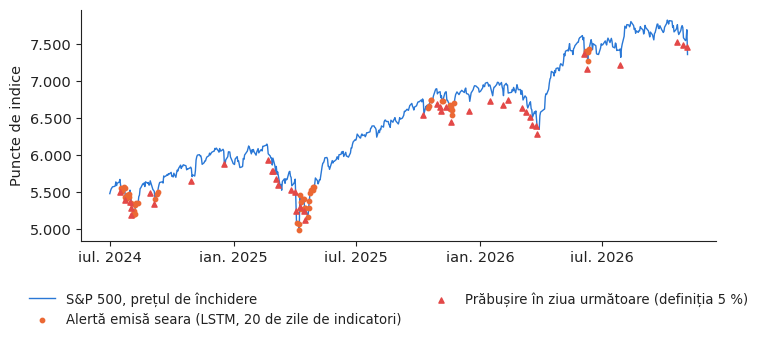

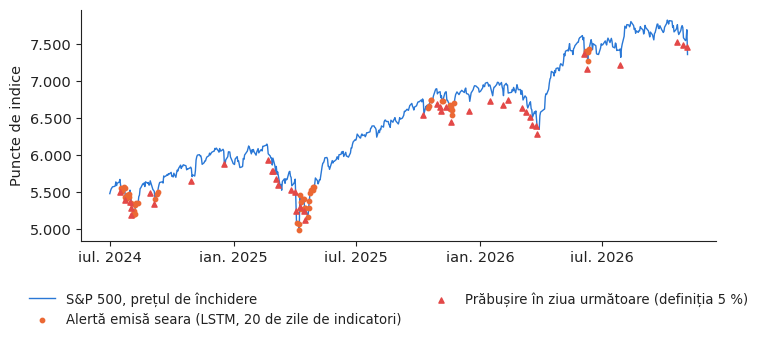

In [15]:
# the alert layer: the model with the best validation AUC (5 % definition); alerts on the test period
k_best = res.AUCval.idxmax()
al = R[0.05][k_best]["alerts"]
y5 = LAB[0.05].loc[days].values[ite]
f_te = fwd.loc[te_days].values
months = (te_days[-1] - te_days[0]).days / 30.44
worst10 = np.argsort(f_te)[:10]
dec = dict(best=NAMES[k_best], alerts=int(al.sum()), perMonth=al.sum() / months, caught=100 * y5[al].sum() / y5.sum(),
           retAlert=100 * f_te[al].mean(), retQuiet=100 * f_te[~al].mean(), sdAlert=100 * f_te[al].std(), sdQuiet=100 * f_te[~al].std(),
           worstCaught=int(al[worst10].sum()))
print(dec)
def fig_timeline(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.0))
    c_ = C.loc[te_days]
    ax.plot(c_.index, c_, color=cu.PAL["RO"], lw=1.0, label=cu.T(lang, "S&P 500 close", "S&P 500, prețul de închidere"))
    a_d = te_days[al]
    ax.scatter(a_d, c_[a_d], s=10, color=cu.PAL["DE_LU"], zorder=3, label=cu.T(lang, "Alert issued in the evening (" + NAMES[k_best][0] + ")",
                                                                               "Alertă emisă seara (" + NAMES[k_best][1] + ")"))
    cr = te_days[y5 == 1]
    ax.scatter(cr, c_[cr] * 0.97, s=14, marker="^", color=cu.EVENT, zorder=3, label=cu.T(lang, "Crash on the next day (5 % definition)", "Prăbușire în ziua următoare (definiția 5 %)"))
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y" if lang == "ro" else "%b %Y"))
    if lang == "ro":
        RO_M = {"01": "ian.", "07": "iul."}
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, p_: (lambda d: f"{RO_M.get(f'{d:%m}', f'{d:%m}')} {d:%Y}")(mdates.num2date(v))))
    ax.set_ylabel(cu.T(lang, "Index points", "Puncte de indice"))
    cu.comma_axis(ax, lang)
    if lang == "ro":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p_: f"{v:,.0f}".replace(",", ".")))
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_timeline, "f4_timeline", headline=True)

In [16]:
def tex_esc(s):
    s = re.sub(r"\s+", " ", str(s)).strip()
    for a, b in (("\\", " "), ("&", "\\&"), ("%", "\\%"), ("_", "\\_"), ("#", "\\#"), ("$", "\\$"), ("{", "("), ("}", ")"), ("~", "-"), ("^", "")):
        s = s.replace(a, b)
    return s
jc, jq = parse(JS[f"{d_crash:%Y-%m-%d}"]), parse(JS[f"{d_calm:%Y-%m-%d}"]) if f"{d_calm:%Y-%m-%d}" in JS else {}
def jfield(j, k):
    v = j.get(k, "--")
    return tex_esc("; ".join(map(str, v)) if isinstance(v, list) else v)
n5 = res.loc
yall = {a: LAB[a].loc[days].values for a in (0.05, 0.01)}
B = lambda k: res.loc[k]
cu.write_numbers({
    "nDays": int(len(days)), "nTrain": int(itr.sum()), "nVal": int(iva.sum()), "nTest": int(ite.sum()),
    "testStart": (f"{te_days[0]:%d %B %Y}", f"{te_days[0]:%d.%m.%Y}"), "testEnd": (f"{te_days[-1]:%d %B %Y}", f"{te_days[-1]:%d.%m.%Y}"),
    "crashTest": int(yall[0.05][ite].sum()), "crashTestOne": int(yall[0.01][ite].sum()),
    "shareTrain": 100 * yall[0.05][itr].mean(), "shareTest": 100 * yall[0.05][ite].mean(),
    "aucVol": B("vol").AUC, "aucLogit": B("logit").AUC, "aucHgb": B("hgb").AUC, "aucLstm": B("lstm").AUC,
    "aucZs": B("clip_zs").AUC, "aucProbe": B("clip_probe").AUC, "aucQwen": B("qwen").AUC,
    "loProbe": B("clip_probe").lo, "hiProbe": B("clip_probe").hi, "loQwen": B("qwen").lo, "hiQwen": B("qwen").hi,
    "loVol": B("vol").lo, "hiVol": B("vol").hi,
    "aucOneVol": B("vol").AUC1, "aucOneProbe": B("clip_probe").AUC1, "aucOneQwen": B("qwen").AUC1, "aucOneLstm": B("lstm").AUC1, "aucOneZs": B("clip_zs").AUC1,
    "lstmMin": min(lstm_seed_auc[0.05]), "lstmMax": max(lstm_seed_auc[0.05]),
    "recProbe": B("clip_probe").Recall, "precProbe": B("clip_probe").Precision, "recQwen": B("qwen").Recall, "precQwen": B("qwen").Precision,
    "recVol": B("vol").Recall, "precVol": B("vol").Precision,
    "best": NAMES[k_best], "bestAUC": B(k_best).AUC, "bestAUCval": B(k_best).AUCval,
    "alerts": dec["alerts"], "perMonth": dec["perMonth"], "caught": dec["caught"], "retAlert": dec["retAlert"], "retQuiet": dec["retQuiet"],
    "sdAlert": dec["sdAlert"], "sdQuiet": dec["sdQuiet"], "worstCaught": dec["worstCaught"],
    "crashDay": (f"{d_crash:%d %B %Y}", f"{d_crash:%d.%m.%Y}"), "crashNext": (f"{days[days.get_loc(d_crash) + 1]:%d %B %Y}", f"{days[days.get_loc(d_crash) + 1]:%d.%m.%Y}"),
    "crashRet": 100 * fwd[d_crash], "calmDay": (f"{d_calm:%d %B %Y}", f"{d_calm:%d.%m.%Y}"),
    "qwenCrashP": float(qv[d_crash]), "qwenCalmP": float(qv[d_calm]),
    "jsScore": jfield(jc, "anomaly_score"), "jsLabel": jfield(jc, "anomaly_label"), "jsType": jfield(jc, "anomaly_type"),
    "jsSignals": jfield(jc, "key_signals"), "jsReason": jfield(jc, "reasoning"),
    "jqScore": jfield(jq, "anomaly_score"), "jqType": jfield(jq, "anomaly_type"), "jqReason": jfield(jq, "reasoning"),
    "jsAsked": len(JS), "jsNoAnomaly": sum(float(parse(s).get("anomaly_label", -1)) == 0 for s in JS.values()),
    "macdCrash": ind.MACD[d_crash], "histCrash": ind.MACDhist[d_crash], "vsTwoHundred": 100 * (C[d_crash] / sma200[d_crash] - 1),
    "hvCrash": ind.HV10[d_crash], "rsiCrash": ind.RSI14[d_crash], "ddCrash": 100 * dd20[d_crash],
}, digits={"shareTrain": 1, "shareTest": 1, "perMonth": 1, "caught": 0, "retAlert": 2, "retQuiet": 2, "sdAlert": 2, "sdQuiet": 2, "crashRet": 2,
           "qwenCrashP": 3, "qwenCalmP": 3, "macdCrash": 2, "histCrash": 2, "vsTwoHundred": 1, "hvCrash": 1, "rsiCrash": 0, "ddCrash": 1, **{k: 3 for k in ("aucVol", "aucLogit", "aucHgb", "aucLstm", "aucZs", "aucProbe", "aucQwen", "loProbe", "hiProbe",
           "loQwen", "hiQwen", "loVol", "hiVol", "aucOneVol", "aucOneProbe", "aucOneQwen", "aucOneLstm", "aucOneZs", "lstmMin", "lstmMax", "recProbe", "precProbe",
           "recQwen", "precQwen", "recVol", "precVol", "bestAUC", "bestAUCval")}})
print(open("numbers_en.tex", encoding="utf-8").read())

% generated by the case notebook -- do not edit
\newcommand{\NnDays}{5,119}
\newcommand{\NnTrain}{3,398}
\newcommand{\NnVal}{1,130}
\newcommand{\NnTest}{591}
\newcommand{\NtestStart}{01 July 2024}
\newcommand{\NtestEnd}{05 November 2026}
\newcommand{\NcrashTest}{42}
\newcommand{\NcrashTestOne}{13}
\newcommand{\NshareTrain}{5.8}
\newcommand{\NshareTest}{7.1}
\newcommand{\NaucVol}{0.552}
\newcommand{\NaucLogit}{0.735}
\newcommand{\NaucHgb}{0.749}
\newcommand{\NaucLstm}{0.726}
\newcommand{\NaucZs}{0.459}
\newcommand{\NaucProbe}{0.598}
\newcommand{\NaucQwen}{0.496}
\newcommand{\NloProbe}{0.525}
\newcommand{\NhiProbe}{0.679}
\newcommand{\NloQwen}{0.401}
\newcommand{\NhiQwen}{0.592}
\newcommand{\NloVol}{0.456}
\newcommand{\NhiVol}{0.651}
\newcommand{\NaucOneVol}{0.548}
\newcommand{\NaucOneProbe}{0.652}
\newcommand{\NaucOneQwen}{0.543}
\newcommand{\NaucOneLstm}{0.643}
\newcommand{\NaucOneZs}{0.385}
\newcommand{\NlstmMin}{0.715}
\newcommand{\NlstmMax}{0.730}
\newcommand{\NrecProbe}{0.024}
\new

In [17]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=2: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{Vision-language anomaly detection} (Jheng, Pele, Tak \\& Găman, 2026, PICBE; Best Paper Award, ICBE 2026): market indicators drawn as multi-panel charts, read zero-shot by GPT-4.1 with a written rationale.",
          "\\textbf{Detectarea anomaliilor cu modele vizual-lingvistice} (Jheng, Pele, Tak și Găman, 2026, PICBE; premiul pentru cea mai bună lucrare, ICBE 2026): indicatorii pieței desenați ca grafice cu mai multe panouri, citiți zero-shot de GPT-4.1, cu o justificare scrisă."),
        t(f"Our replication (S\\&P 500, open models, test {te_days[0]:%b %Y}--{te_days[-1]:%b %Y}): test AUC {F(res.AUC['clip_probe'])} for CLIP embeddings + logistic probe, {F(res.AUC['qwen'])} for Qwen2-VL-2B zero-shot, {F(res.AUC['vol'])} for the 10-day volatility rule; the same 15 indicators as numbers: gradient boosting {F(res.AUC['hgb'])}, LSTM {F(res.AUC['lstm'])}.",
          f"Replicarea noastră (S\\&P 500, modele deschise, test {te_days[0]:%m.%Y}--{te_days[-1]:%m.%Y}): AUC pe test {F(res.AUC['clip_probe'])} pentru reprezentările CLIP cu sondă logistică, {F(res.AUC['qwen'])} pentru Qwen2-VL-2B zero-shot, {F(res.AUC['vol'])} pentru regula volatilității pe 10 zile; aceiași 15 indicatori folosiți ca numere: gradient boosting {F(res.AUC['hgb'])}, LSTM {F(res.AUC['lstm'])}."),
        t("Use: an alert layer with a human analyst in the loop; the threshold is set on a validation period, the rationale is read, not trusted blindly.",
          "Utilizare: un nivel de alertă cu un analist uman în buclă; pragul se stabilește pe o perioadă de validare, iar justificarea se citește, nu se acceptă necritic."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Vision-language anomaly detection} (Jheng, Pele, Tak \& Găman, 2026, PICBE; Best Paper Award, ICBE 2026): market indicators drawn as multi-panel charts, read zero-shot by GPT-4.1 with a written rationale.
  \item Our replication (S\&P 500, open models, test Jul 2024--Nov 2026): test AUC 0.60 for CLIP embeddings + logistic probe, 0.50 for Qwen2-VL-2B zero-shot, 0.55 for the 10-day volatility rule; the same 15 indicators as numbers: gradient boosting 0.75, LSTM 0.73.
  \item Use: an alert layer with a human analyst in the loop; the threshold is set on a validation period, the rationale is read, not trusted blindly.
\end{itemize}



## Exerciții suplimentare
1. Adăugați graficului un al șaselea panou cu VIX (indicele de volatilitate CBOE, în `markets_daily.csv`) și reestimați sonda CLIP. Se modifică AUC pe perioada de test?
2. Modificați orizontul de la h = 1 la h = 5 zile (ec. 15). Sînt scăderile pe o săptămînă mai ușor de recunoscut din grafic decît cele din ziua următoare?
3. Reformulați descrierile text (*prompts*) pentru CLIP și pentru Qwen2-VL (secțiunile 3 și 5). Cît se modifică AUC? Lucrarea arată că scorurile se pot schimba odată cu formularea întrebării (p. 199).